# Natural frequencies of integrally stringer-stiffened cylinders: Sewall and Naumann (1968)

Sewall and Naumann [1] measured the natural frequencies of three aluminium
cylinders of nearly the same radius, skin thickness and length: an
unstiffened cylinder and two cylinders machined with 60 integral
rectangular (blade) stringers, outside the skin in one (externally
stiffened, ES) and inside in the other (internally stiffened, IS). Each was
tested with four sets of end conditions: free-free (FF), simply supported
(SS), clamped-free (CF) and clamped-clamped (CC). Their analysis, a
Rayleigh-Ritz method with the stringers averaged ("smeared") over the skin,
is plotted in their Figures 8 to 11 only; the curves were digitised for this
notebook (file `results/sewall1968_analysis_curves.csv`, reading precision
stated below). The companion analysis of Egle and Sewall [2], with the
stringers as discrete elements, tabulates the frequencies of the "freely
supported" ES cylinder (simply supported, axial displacement free): the
60-stringer shell of [2] is the ES cylinder of [1] (shown below).

Here the three cylinders are modelled with discrete stringers:

- the skin with the BFSC cylinder element of Sanders-type kinematics,
  `BFSCCylinderSanders`;
- each stringer with the BFSC plate element `BFSCPlate2D` of
  [bfscplate2d](https://github.com/saullocastro/bfscplate2d), in the
  plane $(x, r)$ of the stringer, from the middle surface of the skin to the
  tip of the stringer, its nodes along the root tied to the skin.

The 60 stringers are identical and equally spaced, so that one stringer
pitch, a sector of $6°$, represents the cylinder for every circumferential
wave number $n$ (cyclic symmetry, explained below). The natural frequencies
of the problem $(\boldsymbol{K}_{C0} - \omega^2
\boldsymbol{M})\boldsymbol{u} = \boldsymbol{0}$ are compared with every
frequency of Tables II to V of [1], with the analytical curves of Figures 8
to 11 of [1] and with Table 2 of [2]. Three variants of the skin at the
stringer roots are compared: the skin of uniform thickness, and the
circumferential bending stiffness of Appendix A of [1], smeared over the skin
or concentrated at the roots.

The model is given by the module `blade_cylinder_sector.py`, next to this
notebook, shared with the notebook of the buckling tests of Card and Jones.
Besides `bfsccylinder`, it needs `bfscplate2d`, `composites`, SciPy and
Matplotlib.

**References**

[1] Sewall, J. L.; Naumann, E. C., "An experimental and analytical
vibration study of thin cylindrical shells with and without longitudinal
stiffeners", NASA TN D-4705, September 1968.
https://ntrs.nasa.gov/citations/19680024266

[2] Egle, D. M.; Sewall, J. L., "An analysis of free vibration of
orthogonally stiffened cylindrical shells with stiffeners treated as
discrete elements", AIAA Journal 6(3), 518-526, 1968.
https://doi.org/10.2514/3.4528

In [1]:
%matplotlib inline
import csv
import multiprocessing
import os
import re
import time
from concurrent.futures import ProcessPoolExecutor

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

from bfsccylinder.version import __version__ as bfsccylinder_version
from bfscplate2d.version import __version__ as bfscplate2d_version
from blade_cylinder_sector import (BladeCylinderSector, frequencies,
                                   axial_nodes_lines, normalize_phase, DOF,
                                   V, W)

print('bfsccylinder', bfsccylinder_version)
print('bfscplate2d', bfscplate2d_version)

bfsccylinder 0.7.1
bfscplate2d 0.5.0


## Geometry and material

The values are those of Table I of [1] (report page 30), averages of up to
60 measurements, in inches, pounds-force and seconds. The stringers are
spaced 1.00 in along the middle surface of the skin, 60 around the
circumference, and have a fillet of radius 1/16 in on each side of the root.
The cylinder length depends on the end conditions, the length between the
supports (Table I). All cylinders are 6061-T6 aluminium alloy.

In [2]:
# Table I of [1], report page 30; lengths in in, E in psi, rho in lbf s^2/in^4
shells = {
    'unstiffened': dict(R=9.538, h=0.0255),
    'internal': dict(R=9.535, h=0.0266, height=0.2754, A_s=0.029219,
                     z_s=-0.1438),
    'external': dict(R=9.537, h=0.0256, height=0.2764, A_s=0.029319,
                     z_s=0.1439),
}
r_F = 1/16  # fillet radius
width = 0.100  # stringer width, 2 r_s
spacing = 1.00  # along the middle surface
lengths = {'FF': 25.125, 'CF': 24.625, 'SS': 24.00, 'CC': 24.00}
E = 1e7  # psi, shell and stringers
nu = 0.315
G_s = 3.8e6  # psi, shear modulus of the stringers
rho = 2.54e-4  # lbf s^2/in^4
nstringers = 60

inch = 25.4e-3  # m
psi = 4.4482216/inch**2  # Pa
print('E = %.2f GPa, G_s = %.2f GPa, E/(2 (1 + nu)) = %.3g psi'
      % (E*psi/1e9, G_s*psi/1e9, E/(2*(1 + nu))))
print('rho = %.1f kg/m^3' % (rho*4.4482216/inch**4))
for key, g in shells.items():
    print('%-11s R = %.1f mm, h = %.3f mm, 2 pi R/60 = %.3f in'
          % (key, g['R']*1e3*inch, g['h']*1e3*inch,
             2*np.pi*g['R']/nstringers))

E = 68.95 GPa, G_s = 26.20 GPa, E/(2 (1 + nu)) = 3.8e+06 psi
rho = 2714.5 kg/m^3
unstiffened R = 242.3 mm, h = 0.648 mm, 2 pi R/60 = 0.999 in
internal    R = 242.2 mm, h = 0.676 mm, 2 pi R/60 = 0.999 in
external    R = 242.2 mm, h = 0.650 mm, 2 pi R/60 = 0.999 in


Table I gives the shear modulus of the stringers $G_s = E/[2(1 + \nu)]$
within 0.1 %, so that the stringers are isotropic, as the plate elements
are. The 60 stringers fill the circumference with the spacing of 1.00 in.

**Stringer model.** The "stiffener height" of Table I is measured from the
surface of the skin: with this datum, the rectangle $0.100 \times$ height
plus the two fillets, of area $(1 - \pi/4)r_F^2$ each, give the area $A_s$
and the centroid distance $\bar{z}_s$ of Table I, as checked below. The plate
of a stringer goes from the middle surface of the skin to the tip, of height
$H_s = \text{height} + h/2$ and thickness $b_s = 0.100$ in; the fillets are
not modelled.

In [3]:
shells['internal']['J_es'] = 0.832256e-3  # Table I of [1], in^4
shells['external']['J_es'] = 0.836124e-3
for side in ['internal', 'external']:
    g = shells[side]
    rect = width*g['height']
    fillets = 2*(1 - np.pi/4)*r_F**2
    # centroid of a fillet from the skin surface, (10 - 3 pi)/(12 - 3 pi) r_F
    zf = (10 - 3*np.pi)/(12 - 3*np.pi)*r_F
    zbar = (g['h']/2 + (rect*g['height']/2 + fillets*zf)/(rect + fillets))
    Hs = g['height'] + g['h']/2
    print('%s: rectangle + fillets: A = %.6f in^2 (A_s = %.6f), '
          'z = %.4f in (|z_s| = %.4f)' % (side, rect + fillets, g['A_s'],
                                          zbar, abs(g['z_s'])))
    print('    plate of the model: H_s = %.4f in, b_s H_s = %.5f in^2 '
          '(%+.1f %% of A_s), centroid H_s/2 = %.4f in'
          % (Hs, width*Hs, 100*(width*Hs/g['A_s'] - 1), Hs/2))
    # polar moment of inertia about the middle surface of the skin
    J = width*Hs**3/3 + Hs*width**3/12
    print('    polar moment about the skin middle surface: plate %.4e in^4, '
          'J_es of Table I %.4e in^4 (%+.1f %%)'
          % (J, g['J_es'], 100*(J/g['J_es'] - 1)))

internal: rectangle + fillets: A = 0.029217 in^2 (A_s = 0.029219), z = 0.1439 in (|z_s| = 0.1438)
    plate of the model: H_s = 0.2887 in, b_s H_s = 0.02887 in^2 (-1.2 % of A_s), centroid H_s/2 = 0.1443 in
    polar moment about the skin middle surface: plate 8.2614e-04 in^4, J_es of Table I 8.3226e-04 in^4 (-0.7 %)
external: rectangle + fillets: A = 0.029317 in^2 (A_s = 0.029319), z = 0.1439 in (|z_s| = 0.1439)
    plate of the model: H_s = 0.2892 in, b_s H_s = 0.02892 in^2 (-1.4 % of A_s), centroid H_s/2 = 0.1446 in
    polar moment about the skin middle surface: plate 8.3036e-04 in^4, J_es of Table I 8.3612e-04 in^4 (-0.7 %)


The polar moments $J_{e_s}$ of Table I are 0.832256e-3 in$^4$ (IS) and
0.836124e-3 in$^4$ (ES). The plate of the model omits the fillets and
overlaps the skin over $h/2$; its area, centroid and polar moment are within
1.5 % of Table I.

### The 60-stringer shell of Egle and Sewall

Table 1 of [2] (page 522) lists the properties of its 60-stringer shell,
"taken from Ref. 14", the proposed report that became [1]. They are those of
the ES cylinder in Table I of [1] with the SS length:

In [4]:
# Table 1 of [2], page 522, "60 stringer case"
egle_t1 = dict(R=9.537, a=24.00, h=2.56e-2, E=10.0e6, rho=2.54e-4,
               nu=0.315, A_s=2.932e-2, z_s=0.1439, GJ=269.8, Dy=1.197)
es = shells['external']
tn = dict(R=es['R'], a=lengths['SS'], h=es['h'], E=E, rho=rho, nu=nu,
          A_s=es['A_s'], z_s=es['z_s'], GJ=G_s, Dy=1.197)
# Table I of [1] gives G_s, not GJ: J of the 0.100 x height rectangle
# (Saint-Venant, approximation of Roark: a b^3 [1/3 - 0.21 (b/a)
# (1 - b^4/(12 a^4))], a = height, b = width)
a_, b_ = es['height'], width
J_rect = a_*b_**3*(1/3 - 0.21*b_/a_*(1 - b_**4/(12*a_**4)))
tn['GJ'] = G_s*J_rect
labels = dict(R='R (in)', a='a = L, SS (in)', h='h (in)', E='E (psi)',
              rho='rho (lbf s^2/in^4)', nu='nu', A_s='A_s (in^2)',
              z_s='z_s (in)', GJ='(GJ)_s (lbf in^2)', Dy='D_y/D')
print('%-20s %12s %14s   diff' % ('', 'Table 1 [2]', 'Table I [1]'))
for key in labels:
    print('%-20s %12.5g %14.5g  %+5.2f %%'
          % (labels[key], egle_t1[key], tn[key],
             100*(egle_t1[key]/tn[key] - 1)))
Hs_es = es['height'] + es['h']/2
GJ_plate = (E/(2*(1 + nu)))*width**3*Hs_es/3
print('torsion of the plate stringer of the model, G b_s^3 H_s/3 = %.1f '
      'lbf in^2' % GJ_plate)

                      Table 1 [2]    Table I [1]   diff
R (in)                      9.537          9.537  +0.00 %
a = L, SS (in)                 24             24  +0.00 %
h (in)                     0.0256         0.0256  +0.00 %
E (psi)                     1e+07          1e+07  +0.00 %
rho (lbf s^2/in^4)       0.000254       0.000254  +0.00 %
nu                          0.315          0.315  +0.00 %
A_s (in^2)                0.02932       0.029319  +0.00 %
z_s (in)                   0.1439         0.1439  +0.00 %
(GJ)_s (lbf in^2)           269.8         270.42  -0.23 %
D_y/D                       1.197          1.197  +0.00 %
torsion of the plate stringer of the model, G b_s^3 H_s/3 = 366.5 lbf in^2


(The value for $D_y/D$ of [1] is that of its Appendix A, report page 25; the
$(GJ)_s$ of Table I of [1] is computed from $G_s$ and the rectangle without
fillets.) Table 1 of [2] rounds $A_s$ to 0.02932 in$^2$; the rest is the
same, so the ES cylinder of this notebook is the 60-stringer shell of [2].
The plate stringer of the model has the Kirchhoff torsional stiffness
$G b_s^3 H_s/3$, 36 % above the Saint-Venant value of a rectangle of
this aspect ratio (height/width about 2.9), which [2] uses.

## Measured frequencies

Tables II to V of [1] (report pages 31 and 32) give the resonant frequencies
in Hz for $m$ axial and $n$ circumferential wave numbers. The circumferential
wave number $n$ is the number of full waves around the circumference. The
axial wave number $m$ is defined in Figure 4 of [1] (report page 37) by the
radial mode shape along the length: for SS and CC ends, $m$ half-waves
($m - 1$ nodal circles between the ends); for CF ends, $m - 1$ nodal circles
between the clamped and the free end; for FF ends, $m$ nodal circles ($m =
0$, uniform along the length; $m = 1$, linear, one nodal circle; $m = 2$, two
nodal circles).

Two values of the same $(m, n)$ in a table are "dual resonances", two
frequencies of two mode orientations a quarter wavelength apart, found for
many modes [1]. Table III (FF) gives two values for every $m = 0$ and $m =
1$ mode: the first measured with the electrodynamic shaker, the second with
an air shaker, used for small $m$ and $n$, whose frequencies [1] (report
page 10) considers "more nearly correct over the range of $n$ values
covered"; the values with $m \ge 2$ are single values, from the
electrodynamic shaker.

In [5]:
# test[bc][shell][(m, n)] = list of frequencies in Hz
test = {bc: {} for bc in ['SS', 'FF', 'CC', 'CF']}

# Table II, simply supported, report page 31
test['SS']['unstiffened'] = {
    (1, 4): [287.0], (1, 5): [203.0, 211.0], (1, 6): [175.0],
    (1, 7): [163.0, 169.0], (1, 8): [188.0], (1, 9): [224.0],
    (1, 10): [268.0], (1, 11): [326.0], (1, 12): [382.0, 385.0],
    (1, 13): [440.0], (1, 15): [590.0],
    (2, 8): [345.0, 346.0], (2, 10): [339.0, 342.0], (2, 11): [369.0, 370.0],
    (2, 12): [409.0, 411.0], (2, 13): [471.0, 479.0],
    (3, 11): [491.0, 507.0], (3, 12): [510.0, 517.0], (3, 14): [604.0],
}
test['SS']['internal'] = {
    (1, 4): [233.0], (1, 5): [175.0], (1, 6): [137.0, 147.0],
    (1, 7): [142.0, 150.0], (1, 8): [169.0], (1, 9): [203.0],
    (1, 10): [243.0], (1, 11): [290.0], (1, 12): [333.0], (1, 13): [392.0],
    (1, 14): [450.0], (1, 15): [502.0],
    (2, 8): [319.0], (2, 9): [333.0], (2, 10): [366.0], (2, 11): [399.0],
    (2, 12): [443.0], (2, 13): [482.0], (2, 14): [551.0, 560.0],
    (3, 8): [602.0, 605.0], (3, 11): [622.0], (3, 12): [664.0],
    (3, 14): [761.0],
}
test['SS']['external'] = {
    (1, 5): [231.0], (1, 6): [197.0, 201.0], (1, 7): [189.0],
    (1, 8): [199.0], (1, 9): [219.0], (1, 10): [252.0], (1, 11): [290.0],
    (1, 12): [336.0], (1, 13): [378.0, 386.0], (1, 14): [440.0],
    (1, 15): [500.0],
    (2, 10): [469.0, 478.0], (2, 11): [489.0], (2, 12): [507.0, 512.0],
    (2, 13): [546.0], (2, 14): [590.0], (2, 15): [630.0],
}

# Table III, free-free, report page 31: m = 0 and 1 as
# (electrodynamic shaker, air shaker); m >= 2 electrodynamic shaker only
test['FF']['unstiffened'] = {
    (0, 2): (11.8, 7.2), (0, 3): (24.5, 20.1), (0, 4): (40.1, 37.9),
    (0, 5): (63.4, 61.9), (0, 6): (91.7, 91.6), (0, 7): (125.6, 125.0),
    (0, 8): (165.0, 165.0), (0, 9): (210.0, 210.0), (0, 10): (262.0, 262.0),
    (0, 11): (318.0, 318.0), (0, 12): (378.0, 378.0),
    (0, 13): (443.0, 443.0), (0, 14): (512.0, 512.0),
    (1, 2): (14.8, 9.2), (1, 3): (26.8, 22.3), (1, 4): (44.6, 40.3),
    (1, 5): (66.8, 65.0), (1, 6): (94.8, 94.6), (1, 7): (129.0, 129.0),
    (1, 8): (170.0, 170.0), (1, 9): (214.0, 214.0), (1, 10): (266.0, 266.0),
    (1, 11): (322.0, 322.0), (1, 12): (382.0, 382.0),
    (1, 13): (452.0, 452.0), (1, 14): (521.0, 521.0),
    (2, 5): (367.0,), (2, 6): (292.0,), (2, 7): (242.0,), (2, 8): (235.0,),
    (2, 9): (252.0,), (2, 10): (290.0,), (2, 11): (339.0,),
    (2, 13): (459.0,), (2, 14): (533.0,),
    (3, 13): (501.0,), (3, 14): (564.0,),
}
test['FF']['internal'] = {
    (0, 2): (5.0, 6.1), (0, 3): (18.0, 16.1), (0, 4): (32.0, 30.4),
    (0, 5): (51.3, 51.1), (0, 6): (74.0, 74.0), (0, 7): (102.0, 102.0),
    (0, 8): (132.0, 132.0), (0, 9): (170.0, 170.0), (0, 10): (210.0, 210.0),
    (0, 11): (255.0, 255.0), (0, 12): (302.0, 302.0),
    (0, 13): (351.0, 351.0), (0, 14): (410.0, 410.0),
    (1, 2): (21.0, 15.8), (1, 3): (35.0, 31.4), (1, 4): (52.0, 50.4),
    (1, 5): (71.0, 70.3), (1, 6): (96.0, 95.8), (1, 7): (124.0, 124.0),
    (1, 8): (158.0, 158.0), (1, 9): (195.0, 195.0), (1, 10): (234.0, 234.0),
    (1, 11): (280.0, 280.0), (1, 12): (330.0, 330.0),
    (1, 13): (382.0, 382.0),
    (2, 6): (273.0,), (2, 7): (245.0,), (2, 8): (252.0,), (2, 9): (276.0,),
    (2, 10): (312.0,), (2, 11): (358.0,), (2, 12): (405.0,),
    (2, 13): (455.0,),
}
test['FF']['external'] = {
    (0, 2): (4.8, 5.9), (0, 3): (17.5, 15.7), (0, 4): (30.8, 30.6),
    (0, 5): (50.0, 50.1), (0, 6): (71.0, 71.0), (0, 7): (98.0, 98.0),
    (0, 8): (129.0, 129.0), (0, 9): (165.0, 165.0), (0, 10): (208.0, 208.0),
    (0, 11): (249.0, 249.0), (0, 12): (295.0, 295.0),
    (0, 13): (348.0, 348.0), (0, 14): (403.0, 403.0),
    (1, 2): (20.5, 15.2), (1, 3): (34.5, 31.1), (1, 4): (52.5, 49.4),
    (1, 5): (72.0, 69.7), (1, 6): (94.0, 94.0), (1, 7): (122.0, 122.0),
    (1, 8): (159.0, 159.0), (1, 9): (189.0, 189.0), (1, 10): (232.0, 232.0),
    (1, 11): (273.0, 273.0), (1, 12): (318.0, 318.0),
    (1, 14): (430.0, 430.0), (1, 15): (493.0, 493.0),
    (2, 8): (320.0,), (2, 9): (330.0,), (2, 10): (352.0,), (2, 11): (388.0,),
    (2, 12): (422.0,), (2, 13): (470.0,),
}

# Table IV, clamped-clamped, report page 32
test['CC']['unstiffened'] = {
    (1, 5): [321.0, 325.0], (1, 6): [263.0], (1, 7): [233.0],
    (1, 8): [227.0], (1, 9): [244.0], (1, 10): [281.0], (1, 12): [386.0],
    (1, 13): [453.0], (1, 14): [515.0],
    (2, 7): [479.0], (2, 8): [418.0, 423.0], (2, 11): [397.0, 404.0],
    (2, 13): [490.0], (2, 14): [552.0], (2, 15): [622.0],
    (3, 10): [583.0], (3, 11): [562.0], (3, 15): [690.0],
}
test['CC']['internal'] = {
    (1, 4): [356.0], (1, 5): [275.0], (1, 6): [228.0], (1, 7): [207.0],
    (1, 8): [212.0], (1, 9): [231.0], (1, 10): [262.0],
    (1, 11): [302.0, 308.0], (1, 12): [356.0], (1, 13): [405.0],
    (1, 14): [457.0], (1, 15): [522.0],
    (2, 7): [449.0], (2, 8): [423.0], (2, 9): [418.0], (2, 10): [435.0],
    (2, 11): [467.0], (2, 13): [551.0], (2, 14): [603.0], (2, 15): [660.0],
    (3, 12): [757.0, 763.0], (3, 13): [803.0], (3, 14): [846.0],
}
test['CC']['external'] = {
    (1, 5): [347.0], (1, 6): [313.0], (1, 7): [282.0], (1, 8): [272.0],
    (1, 9): [287.0], (1, 10): [305.0], (1, 11): [333.0], (1, 12): [370.0],
    (1, 14): [466.0], (1, 15): [525.0],
    (2, 10): [578.0], (2, 12): [605.0], (2, 13): [630.0], (2, 15): [711.0],
}

# Table V, clamped-free, report page 32
test['CF']['unstiffened'] = {
    (1, 3): [155.0, 157.0], (1, 4): [107.0], (1, 5): [89.0, 91.0],
    (1, 6): [102.0], (1, 7): [130.0], (1, 8): [166.0], (1, 9): [208.0],
    (1, 10): [260.0], (1, 11): [317.0], (1, 12): [374.0], (1, 14): [523.0],
    (2, 5): [341.0], (2, 6): [276.0], (2, 7): [240.0], (2, 8): [227.0, 231.0],
    (2, 9): [246.0], (2, 10): [281.0], (2, 11): [337.0],
    (2, 12): [393.0, 396.0], (2, 13): [455.0, 461.0], (2, 14): [531.0],
    (2, 15): [603.0],
    (3, 9): [400.0], (3, 11): [409.0, 412.0], (3, 13): [476.0],
    (3, 14): [558.0], (3, 15): [633.0],
}
test['CF']['internal'] = {
    (1, 3): [147.0], (1, 4): [99.0], (1, 5): [80.0, 83.0],
    (1, 6): [90.0, 93.0], (1, 7): [113.0], (1, 8): [143.0], (1, 9): [177.0],
    (1, 10): [217.0], (1, 11): [267.0], (1, 12): [312.0], (1, 13): [363.0],
    (1, 14): [425.0], (1, 15): [486.0],
    (2, 4): [390.0], (2, 5): [303.0], (2, 6): [247.0], (2, 7): [225.0],
    (2, 8): [233.0], (2, 9): [257.0], (2, 10): [290.0, 295.0],
    (2, 11): [331.0], (2, 12): [384.0], (2, 13): [438.0], (2, 14): [494.0],
    (2, 15): [535.0],
    (3, 6): [544.0], (3, 9): [434.0], (3, 10): [456.0], (3, 11): [491.0],
    (3, 12): [524.0], (3, 13): [584.0], (3, 14): [627.0],
}
test['CF']['external'] = {
    (1, 2): [277.0], (1, 3): [161.0, 166.0], (1, 4): [110.0, 114.0],
    (1, 5): [94.0, 97.0], (1, 6): [100.0], (1, 7): [121.0], (1, 8): [147.0],
    (1, 9): [181.0], (1, 10): [217.0, 222.0], (1, 11): [259.0],
    (1, 12): [316.0], (1, 13): [360.0], (1, 14): [418.0], (1, 15): [495.0],
    (2, 4): [473.0], (2, 5): [377.0], (2, 6): [340.0], (2, 7): [308.0, 310.0],
    (2, 8): [298.0, 301.0], (2, 10): [328.0, 330.0], (2, 11): [365.0],
    (2, 13): [444.0], (2, 15): [544.0],
}


def reference(bc, m, values):
    # value compared: the air-shaker value for FF, m = 0 and 1 ([1], report
    # page 10), otherwise the mean of a dual resonance
    if bc == 'FF':
        return values[1] if len(values) == 2 else values[0]
    return np.mean(values)


print('number of measured (m, n):')
for bc in test:
    print('  %s: ' % bc + ', '.join('%s %d' % (s, len(test[bc][s]))
                                   for s in test[bc]))

number of measured (m, n):
  SS: unstiffened 19, internal 23, external 17
  FF: unstiffened 37, internal 33, external 32
  CC: unstiffened 18, internal 23, external 14
  CF: unstiffened 27, internal 32, external 23


## Model: one stringer pitch with cyclic symmetry

The cylinder is invariant under a rotation by $\phi = 2\pi/60$ about its
axis. The model is the sector $0 \le \theta \le \phi$, with the stringer at
its middle, $\theta = \phi/2$; its skin has `nbay` elements across the
sector and `nx` nodes along $x$, its stringer `nh` elements along the
height. The degrees of freedom of the BFSC elements are in the axial,
circumferential and radial directions, which rotate with the sector, so that
a mode of the whole cylinder with $n$ circumferential waves has, in the
sector $k$, the degrees of freedom of the sector $0$ multiplied by $e^{i n k
\phi}$. The nodes of the edge $\theta = \phi$ are eliminated with
$\boldsymbol{u}(\phi) = e^{i n \phi}\boldsymbol{u}(0)$, and one complex
Hermitian eigenvalue problem per harmonic $n = 0, 1, \ldots, 30$ gives all
the modes of the cylinder. A harmonic $n$ contains the circumferential waves
$n \pm 60 j$, which the discrete stringers couple, as Egle and Sewall [2]
show for discrete stringers; with 60 stringers the coupling of a mode with
$n \le 15$ to the waves $60 - n$ and beyond is weak [2], but it is in the
model. The modes of $n$ and $-n$ are the pair in $\cos n\theta$ and $\sin
n\theta$ of the same frequency: the discrete model with identical stringers
has no dual resonances for $n < 30$. In the tests, [1] (report page 11)
does not know whether the preferred orientations of the dual resonances "are
due to construction defects or to rotational and translational energies of
the stiffeners"; departures from the ideal geometry, such as the two
longitudinal seams $180°$ apart (report page 6), would split the pair.

The stringer root is tied to the skin along $\theta = \phi/2$: the axial,
radial and circumferential displacements and the rotation about $x$ of the
stringer are those of the skin, $U = u$, $V = w$, $W = v$, $W_{,Y} =
-w_{,y} + v/R$, with the rotation of the Sanders-type kinematics, and the
derivatives of these relations along $x$; see the docstring of
`blade_cylinder_sector.py`.

The end conditions of the tests [1] (report pages 6 to 8) and their model:

| tests | model at the end |
|---|---|
| free-free: suspended by soft rubber bands | none |
| simply supported: rings with sharp tips inside and outside the skin at each end, which restrain the normal displacement and let the cylinder move axially; for the stiffened cylinders, clips at three locations between stringers against the rotation of the cylinder; "motion normal to the shell between stiffeners was not restrained on the stiffened side of the shell" (report page 7) | $v = w = 0$; $u$, $w_{,x}$ free; $V = W = 0$ along the end edge of the stringer |
| clamped: the end potted 1/2 in deep in a groove of an end plate | $u = v = w = w_{,x} = 0$ and the end edge of the stringer clamped |

The derivatives along an end edge of its constrained displacements are
constrained as well. With SS ends and $n = 0$, the mean of $u$ along the
edge $x = 0$ is tied to zero, which removes the axial rigid-body motion. With
FF ends, the six rigid-body motions of the cylinder appear as zero
frequencies at $n = 0$ and $n = 1$; the tests start at $n = 2$.

Each mode is identified by its harmonic $n$ and by the number of sign
changes along $x$ of the normal displacement $w$ of the skin (each line of
nodes along $x$ taken with its own complex phase), counted as in Figure 4 of
[1]: $m$ = sign
changes + 1 for SS, CC and CF ends, $m$ = sign changes for FF ends. A mode is kept when all the lines of
nodes with at least half the largest mean square of $w$ have the same number
of sign changes, and for each $(m, n)$ the lowest frequency is kept; modes
without a single axial wave number (in-surface modes with small $w$, mixed
local modes) are not classified.

The computations below are many independent eigenvalue analyses (one per
cylinder, end conditions, mesh and variant); `pmap` runs them in parallel
processes where the operating system can fork them (the number of processes
is the environment variable `NPROC`, by default the number of processors),
otherwise one after another.

In [6]:
def build(shell, bc, nx, nbay, nh, **options):
    # options: h (skin thickness, default Table I) and the keyword arguments
    # Dy_factor and skin_inplane_inertia of BladeCylinderSector
    g = shells[shell]
    h = options.pop('h', g['h'])
    blade = {}
    if shell != 'unstiffened':
        blade = dict(bs=width, Hs=g['height'] + h/2, side=shell, nh=nh)
    return BladeCylinderSector(R=g['R'], L=lengths[bc], h=h, E=E, nu=nu,
                               rho=rho, nstringers=nstringers, nx=nx,
                               nbay=nbay, **blade, **options)


def spectrum(task):
    # lowest frequency (and, with keep_modes, the mode) of each (m, n);
    # task = (shell, bc, mesh, options), options of build() and ns, k,
    # keep_modes; returns the number of complex degrees of freedom of the
    # sector, the frequencies and the modes
    shell, bc, mesh, options = task
    options = dict(options)
    ns = options.pop('ns', range(2, 17))
    k = options.pop('k', 10)
    keep_modes = options.pop('keep_modes', False)
    model = build(shell, bc, *mesh, **options)
    freq, modes = {}, {}
    for n in ns:
        f, X = frequencies(model, bc, n, k=k)
        for i, fi in enumerate(f):
            if fi < 1.:  # rigid-body motions, FF
                continue
            counts, msq = axial_nodes_lines(model, X[:, i])
            counts = counts[msq >= 0.5*msq.max()]
            if np.any(counts != counts[0]):  # no single axial wave number
                continue
            m = int(counts[0]) + (0 if bc == 'FF' else 1)
            if (m, n) not in freq:
                freq[(m, n)] = fi
                if keep_modes:
                    modes[(m, n)] = X[:, i]
    return model.Nr, freq, modes


def pmap(func, tasks):
    tasks = list(tasks)
    if 'fork' in multiprocessing.get_all_start_methods():
        nproc = int(os.environ.get('NPROC', os.cpu_count()))
        with ProcessPoolExecutor(nproc, mp_context=multiprocessing.get_context(
                'fork')) as ex:
            return list(ex.map(func, tasks))
    return [func(t) for t in tasks]

## Mesh convergence

The three cylinders and the four end conditions with a sequence of meshes
`(nx, nbay, nh)`. For each case the table gives the number of complex
degrees of freedom of the sector, the frequency of the lowest measured mode
of Tables II to V, and the largest change, over all the measured $(m, n)$ of
the case, from the previous mesh. The FF modes with $m = 1$ and small $n$,
in which the cylinder twists between its free ends, converge slowly along
$x$ and need a finer mesh along $x$ than the other end conditions.

In [7]:
coarse = [(13, 2, 2), (25, 4, 3), (49, 8, 6), (97, 12, 8)]
meshes = {'SS': coarse, 'CC': coarse, 'CF': coarse,
          'FF': [(49, 8, 6), (97, 8, 6), (145, 8, 6), (193, 8, 6), (241, 8, 6)]}
final = {bc: meshes[bc][-1] for bc in meshes}
tasks = [(shell, bc, mesh, dict(keep_modes=(mesh == final[bc])))
         for shell in ['unstiffened', 'internal', 'external']
         for bc in ['SS', 'FF', 'CC', 'CF'] for mesh in meshes[bc]]
t0 = time.time()
conv = {t[:3]: r for t, r in zip(tasks, pmap(spectrum, tasks))}
print('%.0f s' % (time.time() - t0))

print('cylinder    ends  mesh            dofs  lowest tested mode   '
      'largest change of the tested modes')
for shell in ['unstiffened', 'internal', 'external']:
    for bc in ['SS', 'FF', 'CC', 'CF']:
        keys = list(test[bc][shell])
        mn0 = min(keys, key=lambda mn: reference(bc, mn[0],
                                                 test[bc][shell][mn]))
        prev = None
        for mesh in meshes[bc]:
            Nr, freq, _ = conv[(shell, bc, mesh)]
            f = np.array([freq.get(mn, np.nan) for mn in keys])
            change = ''
            if prev is not None:
                d = np.abs(f/prev - 1)
                i = np.nanargmax(d)
                change = '%5.2f %% at (%d, %2d)' % (100*d[i], *keys[i])
            print('%-11s %-5s %-13s %5d  (%d, %2d) %7.1f Hz     %s'
                  % (shell, bc, mesh, Nr, *mn0, freq.get(mn0, np.nan),
                     change))
            prev = f

663 s
cylinder    ends  mesh            dofs  lowest tested mode   largest change of the tested modes
unstiffened SS    (13, 2, 2)      260  (1,  7)   168.7 Hz     
unstiffened SS    (25, 4, 3)     1000  (1,  7)   166.8 Hz      1.74 % at (3, 11)
unstiffened SS    (49, 8, 6)     3920  (1,  7)   166.3 Hz      0.33 % at (3, 11)
unstiffened SS    (97, 12, 8)   11640  (1,  7)   166.2 Hz      0.08 % at (3, 11)
unstiffened FF    (49, 8, 6)     3920  (0,  2)     7.2 Hz     
unstiffened FF    (97, 8, 6)     7760  (0,  2)     7.2 Hz     14.68 % at (1,  2)
unstiffened FF    (145, 8, 6)   11600  (0,  2)     7.2 Hz      3.54 % at (1,  2)
unstiffened FF    (193, 8, 6)   15440  (0,  2)     7.2 Hz      1.32 % at (1,  2)
unstiffened FF    (241, 8, 6)   19280  (0,  2)     7.2 Hz      0.63 % at (1,  2)
unstiffened CC    (13, 2, 2)      260  (1,  8)   238.5 Hz     
unstiffened CC    (25, 4, 3)     1000  (1,  8)   236.2 Hz      1.97 % at (3, 11)
unstiffened CC    (49, 8, 6)     3920  (1,  8)   235.7 Hz    

The finest mesh of each end condition is used below: from the previous
mesh, the measured modes change by less than 1 % (the last line of each
case in the table).

## Comparison with the tests

All three cylinders and the four end conditions with the finest mesh:

In [8]:
results = {(shell, bc): conv[(shell, bc, final[bc])]
           for shell in ['unstiffened', 'internal', 'external']
           for bc in ['SS', 'FF', 'CC', 'CF']}

summary = {}
for bc, table in [('SS', 'II'), ('FF', 'III'), ('CC', 'IV'), ('CF', 'V')]:
    print('\nEnd conditions %s, Table %s of [1]' % (bc, table))
    print(' m   n | %-26s | %-26s | %-26s' % ('unstiffened', 'internal',
                                              'external'))
    print('       | ' + ' | '.join(['  test (Hz)  FE (Hz)  diff'] * 3))
    keys = sorted(set().union(*[test[bc][s] for s in test[bc]]))
    for m, n in keys:
        row = []
        for shell in ['unstiffened', 'internal', 'external']:
            values = test[bc][shell].get((m, n))
            if values is None:
                row.append(' '*26)
                continue
            ref = reference(bc, m, values)
            fe = results[(shell, bc)][1].get((m, n), np.nan)
            row.append('%11.1f %8.1f %+5.1f%%' % (ref, fe,
                                                    100*(fe/ref - 1)))
            summary.setdefault((shell, bc), []).append(fe/ref - 1)
        print('%2d %3d | ' % (m, n) + ' | '.join(row))


End conditions SS, Table II of [1]
 m   n | unstiffened                | internal                   | external                  
       |   test (Hz)  FE (Hz)  diff |   test (Hz)  FE (Hz)  diff |   test (Hz)  FE (Hz)  diff
 1   4 |       287.0    287.6  +0.2% |       233.0    233.2  +0.1% |                           
 1   5 |       207.0    201.8  -2.5% |       175.0    165.2  -5.6% |       231.0    228.5  -1.1%
 1   6 |       175.0    166.6  -4.8% |       142.0    139.7  -1.6% |       199.0    195.8  -1.6%
 1   7 |       166.0    166.2  +0.1% |       146.0    142.4  -2.4% |       189.0    186.2  -1.5%
 1   8 |       188.0    189.3  +0.7% |       169.0    161.8  -4.3% |       199.0    192.9  -3.1%
 1   9 |       224.0    226.8  +1.3% |       203.0    190.4  -6.2% |       219.0    211.1  -3.6%
 1  10 |       268.0    274.0  +2.3% |       243.0    224.9  -7.4% |       252.0    237.7  -5.7%
 1  11 |       326.0    328.6  +0.8% |       290.0    264.0  -9.0% |       290.0    270.7  -6.6%
 

The relative difference is (FE − test)/test; a dual resonance is compared
with the mean of its two frequencies, the FF modes with $m = 0$ and $m = 1$
with the air-shaker value. The statistics of the relative differences per
cylinder and end conditions:

In [9]:
print('cylinder     ends  modes   mean diff   min diff   max diff')
for (shell, bc), d in summary.items():
    d = 100*np.array(d)
    print('%-12s %-4s %5d   %+7.1f %%  %+7.1f %%  %+7.1f %%'
          % (shell, bc, len(d), d.mean(), d.min(), d.max()))

cylinder     ends  modes   mean diff   min diff   max diff
unstiffened  SS      19      +0.6 %     -4.8 %     +3.7 %
internal     SS      23      -4.9 %    -10.3 %     +0.1 %
external     SS      17      -4.3 %    -10.2 %     -0.6 %
unstiffened  FF      37      +1.7 %     -3.5 %     +7.5 %
internal     FF      33      -6.7 %    -14.9 %     +2.3 %
external     FF      32      -6.6 %    -15.4 %     +3.5 %
internal     CC      23      -3.4 %     -9.3 %     +0.4 %
unstiffened  CC      18      +2.7 %     -1.7 %     +8.4 %
external     CC      14      -0.1 %     -8.8 %     +5.2 %
external     CF      23      -4.3 %    -15.2 %     +3.7 %
unstiffened  CF      27      +2.5 %     +0.1 %     +7.8 %
internal     CF      32      -5.7 %    -11.0 %     -0.6 %


## Circumferential bending stiffness of the skin at the stringer roots

In the model each stringer is joined to the skin along a line, and the skin
has the thickness $h$ everywhere. The actual roots, $2 r_S = 0.100$ in wide
with fillets of radius $r_F = 1/16$ in on both sides, stiffen the skin in
circumferential bending over $2(r_F + r_S) = 0.225$ in of each $d = 1.00$ in
bay. Appendix A of [1] (report pages 23 to 26) estimates this effect by
equating the strain energy of the skin in pure circumferential bending with
that of an orthotropic skin, following Huffington, Schumacher and Irwin (its
Ref. 24): with an effective thickness $h(y)$ across the bay, eq. (A1),

$$\frac{D_y}{D} = \left[\frac{h^3}{d}\int_{-d/2}^{d/2}
\frac{\mathrm{d}y}{h(y)^3}\right]^{-1}$$

The thickness $h(y)$ of its sketch c is $h$ between the roots, $b - \sqrt{r_F^2
- (|y| - r_F - r_S)^2}$ in the fillets and $b + \sqrt{r_S^2 - y^2}$ under the
stringer, with $b = h + r_F$ (succession of quarter-circular arcs; the rest of
the stringer is "ineffective"). The integral splits into the bay $I_C$
(A3), the two fillets $I_F$ (A4) and the stringer $I_S$ (A5), given in closed
form; $D_y/D$ is (A6). [1] gives $D_y/D = 1.197$ (ES) and $1.195$ (IS), the
values of its analytical curves (report page 25); $1.195$ (ES) and $1.192$
(IS) with $h(y) = b$ under the stringer (page 26); the upper bound $1.29$ for
rigid roots (A7); and $1.11$ for a stringer without fillets and $h/b \to 0$
(A8). The same values are recomputed here from Table I, by numerical
quadrature of (A1) and from the closed forms:

In [10]:
r_S = width/2
d = spacing


def h_root(y, h):
    # effective thickness h(y) of sketch c of [1], y from the stringer axis
    b = h + r_F
    y = abs(y)
    if y < r_S:
        return b + np.sqrt(r_S**2 - y**2)
    if y < r_S + r_F:
        return b - np.sqrt(max(r_F**2 - (y - r_F - r_S)**2, 0.))
    return h


def compliance(y1, y2, h):
    # integral of dy/h(y)^3 from y1 to y2
    pts = [p for p in (-r_S - r_F, -r_S, r_S, r_S + r_F) if y1 < p < y2]
    return quad(lambda y: h_root(y, h)**-3, y1, y2, points=pts or None,
                limit=200)[0]


def appendix_A(h):
    # closed forms (A3) to (A5) of [1]
    b = h + r_F
    I_C = (d - 2*(r_F + r_S))/h**3
    I_F = r_F/2*((b**2 + r_F**2)/(b*(b**2 - r_F**2)**2)
                 + b/((b - r_F)**2*(b + r_F)**2)
                 + 6*b*r_F/(b**2 - r_F**2)**2.5
                 * np.arctan(np.sqrt((b + r_F)/(b - r_F))))
    I_S = r_S*((b**2 + r_S**2)/(b*(b**2 - r_S**2)**2)
               + b/((b - r_S)**2*(b + r_S)**2)
               - 6*b*r_S/(b**2 - r_S**2)**2.5
               * np.arctan(np.sqrt((b - r_S)/(b + r_S))))
    return I_C, I_F, I_S


printed = {'internal': (1.195, 1.192), 'external': (1.197, 1.195)}
for shell in ['internal', 'external']:
    h = shells[shell]['h']
    b = h + r_F
    I_C, I_F, I_S = appendix_A(h)
    Dy_closed = 1/(h**3/d*(I_C + 2*I_F + I_S))  # (A6)
    Dy_quad = 1/(h**3/d*compliance(-d/2, d/2, h))  # (A1)
    Dy_b = 1/(h**3/d*(I_C + 2*I_F + 2*r_S/b**3))  # h(y) = b under the stringer
    print('%s, h = %.4f in: I_C = %.1f, I_F = %.1f, I_S = %.2f in^-2'
          % (shell, h, I_C, I_F, I_S))
    print('    D_y/D (A6) = %.4f, quadrature of (A1) = %.4f, printed %.3f'
          % (Dy_closed, Dy_quad, printed[shell][0]))
    print('    h(y) = b under the stringer: %.4f, printed %.3f'
          % (Dy_b, printed[shell][1]))
print('rigid roots (A7): %.3f' % (1/(1 - 2*(r_F + r_S)/d)))
print('no fillets, h/b -> 0 (A8): %.3f' % (1/(1 - 2*r_S/d)))
for shell in ['internal', 'external']:
    h = shells[shell]['h']
    b = shells[shell]['height'] + h
    print('no fillets, b = height + h, %s (A8): %.4f'
          % (shell, 1/(1 - 2*r_S/d*(1 - h**3/b**3))))

internal, h = 0.0266 in: I_C = 41177.2, I_F = 1613.9, I_S = 49.97 in^-2
    D_y/D (A6) = 1.1952, quadrature of (A1) = 1.1952, printed 1.195
    h(y) = b under the stringer: 1.1927, printed 1.192
external, h = 0.0256 in: I_C = 46193.6, I_F = 1783.4, I_S = 51.21 in^-2
    D_y/D (A6) = 1.1966, quadrature of (A1) = 1.1966, printed 1.197
    h(y) = b under the stringer: 1.1943, printed 1.195
rigid roots (A7): 1.290
no fillets, h/b -> 0 (A8): 1.111
no fillets, b = height + h, internal (A8): 1.1110
no fillets, b = height + h, external (A8): 1.1110


The recomputed factors are those printed in [1] to the last digit, within
the rounding of the last digit for $h(y) = b$ under the stringer (1.1927 and
1.1943 against the printed 1.192 and 1.195). [1] (report page 26) concludes
from (A7) and (A8) that $D_y/D$ "is not particularly affected by wide
variations in the choice of $h(y)$ through the stiffener width"; it depends
on the fillets, between 1.11 (none) and 1.29 (rigid).

### Two models of the stiffened roots

The analysis of [1] and Table 2 of [2] apply $D_y/D$ to the whole skin (a
smeared orthotropic skin). In the discrete model two variants are compared
with the skin of uniform thickness ($D_y/D = 1$):

- **uniform**: the circumferential bending stiffness $D_{22}$ of every skin
  element multiplied by $D_y/D = 1.195$ (IS) or $1.197$ (ES) of [1]
  (`Dy_factor`, a number);
- **roots**: $D_{22}$ of each column $j$ of skin elements, between $y_j$ and
  $y_j + \Delta y$, multiplied by the factor that gives the element the
  compliance of (A1) over its width,
  $\Delta y/[h^3\int_{y_j}^{y_j + \Delta y} h(y)^{-3}\,\mathrm{d}y]$
  (`Dy_factor`, an array): the stiffening of Appendix A of [1] is where the
  roots are, the skin between the roots keeps $D_{22} = D$. In pure
  circumferential bending (uniform moment) both variants have the same
  compliance per bay.

In both variants only $D_{22}$ changes; [1] (report pages 12 and 17) also
raises the coupling term, $D_1/D = \mu(D_x/D + D_y/D)/2 = 0.346$ instead of
$\mu = 0.315$, which the variants do not. The factors of the roots variant
for the mesh of the SS ends:

In [11]:
Dy = {'internal': 1.195, 'external': 1.197}  # [1], appendix A, page 25


def root_factors(shell, nbay):
    h = shells[shell]['h']
    arc = shells[shell]['R']*2*np.pi/nstringers
    dy = arc/nbay
    y = np.arange(nbay)*dy - arc/2
    return np.array([dy/(h**3*compliance(yj, yj + dy, h)) for yj in y])


for shell in ['internal', 'external']:
    fac = root_factors(shell, final['SS'][1])
    print('%s, nbay = %d: %s; mean compliance factor %.4f'
          % (shell, final['SS'][1], np.round(fac, 3),
             1/np.mean(1/fac)))

internal, nbay = 12: [ 1.     1.     1.     1.     1.076 11.15  11.15   1.076  1.     1.
  1.     1.   ]; mean compliance factor 1.1955
external, nbay = 12: [ 1.     1.     1.     1.     1.079 11.644 11.644  1.079  1.     1.
  1.     1.   ]; mean compliance factor 1.1969


The two variants are computed for the stiffened cylinders and the four end
conditions. Their convergence: the uniform variant with the two finest
meshes of the convergence study above; the roots variant with the finest
mesh and the same mesh with twice the elements across the sector (`nbay`),
which resolves the roots better; the roots variant is taken with the latter.

In [12]:
def doubled(mesh):
    return (mesh[0], 2*mesh[1], mesh[2])


variants = ['D_y/D = 1', 'uniform', 'roots']
vmesh = {('uniform', bc): (meshes[bc][-2], final[bc]) for bc in final}
vmesh.update({('roots', bc): (final[bc], doubled(final[bc]))
              for bc in final})
tasks = []
for shell in ['internal', 'external']:
    for bc in ['SS', 'FF', 'CC', 'CF']:
        for mesh in vmesh[('uniform', bc)]:
            tasks.append((shell, bc, mesh, dict(Dy_factor=Dy[shell])))
        for mesh in vmesh[('roots', bc)]:
            tasks.append((shell, bc, mesh,
                          dict(Dy_factor=root_factors(shell, mesh[1]))))
t0 = time.time()
out = pmap(spectrum, tasks)
print('%.0f s' % (time.time() - t0))
vconv = {}
for t, r in zip(tasks, out):
    variant = 'uniform' if np.ndim(t[3]['Dy_factor']) == 0 else 'roots'
    vconv[(t[0], t[1], variant, t[2])] = r[1]

results_v = {}  # results_v[(shell, bc, variant)] = {(m, n): f}
for shell in ['unstiffened', 'internal', 'external']:
    for bc in ['SS', 'FF', 'CC', 'CF']:
        results_v[(shell, bc, 'D_y/D = 1')] = results[(shell, bc)][1]
print('cylinder  ends  variant   meshes                        '
      'largest change of the tested modes')
for shell in ['internal', 'external']:
    for bc in ['SS', 'FF', 'CC', 'CF']:
        keys = list(test[bc][shell])
        for variant in ['uniform', 'roots']:
            m0, m1 = vmesh[(variant, bc)]
            f0 = np.array([vconv[(shell, bc, variant, m0)].get(mn, np.nan)
                           for mn in keys])
            f1 = np.array([vconv[(shell, bc, variant, m1)].get(mn, np.nan)
                           for mn in keys])
            dd = np.abs(f1/f0 - 1)
            i = np.nanargmax(dd)
            print('%-9s %-5s %-8s  %-13s -> %-13s  %5.2f %% at (%d, %2d)'
                  % (shell, bc, variant, m0, m1, 100*dd[i], *keys[i]))
            results_v[(shell, bc, variant)] = vconv[(shell, bc, variant, m1)]

1367 s
cylinder  ends  variant   meshes                        largest change of the tested modes
internal  SS    uniform   (49, 8, 6)    -> (97, 12, 8)     0.14 % at (3,  8)
internal  SS    roots     (97, 12, 8)   -> (97, 24, 8)     0.04 % at (2, 14)
internal  FF    uniform   (193, 8, 6)   -> (241, 8, 6)     0.09 % at (1,  2)
internal  FF    roots     (241, 8, 6)   -> (241, 16, 6)    0.26 % at (2, 13)
internal  CC    uniform   (49, 8, 6)    -> (97, 12, 8)     0.20 % at (3, 12)
internal  CC    roots     (97, 12, 8)   -> (97, 24, 8)     0.04 % at (1, 15)
internal  CF    uniform   (49, 8, 6)    -> (97, 12, 8)     0.16 % at (3,  9)
internal  CF    roots     (97, 12, 8)   -> (97, 24, 8)     0.05 % at (2, 15)
external  SS    uniform   (49, 8, 6)    -> (97, 12, 8)     0.06 % at (2, 10)
external  SS    roots     (97, 12, 8)   -> (97, 24, 8)     0.05 % at (2, 15)
external  FF    uniform   (193, 8, 6)   -> (241, 8, 6)     0.09 % at (1,  2)
external  FF    roots     (241, 8, 6)   -> (241, 16, 6)

The relative differences (FE − test)/test of the three variants, per
cylinder and end conditions:

In [13]:
def stats(d):
    d = 100*np.array(d)
    return len(d), np.nanmean(d), np.nanmin(d), np.nanmax(d)


print('cylinder     ends  modes  ' + '  '.join('%-23s' % v for v in variants))
print(' '*26 + '  '.join(['  mean    min    max   ']*3))
summary_v = {}
for shell in ['unstiffened', 'internal', 'external']:
    for bc in ['SS', 'FF', 'CC', 'CF']:
        row = ''
        for variant in variants:
            fv = results_v.get((shell, bc, variant))
            if fv is None:
                row += ' '*25
                continue
            dv = [fv.get(mn, np.nan)/reference(bc, mn[0], v) - 1
                  for mn, v in test[bc][shell].items()]
            summary_v[(shell, bc, variant)] = s = stats(dv)
            row += '%+6.1f %+6.1f %+6.1f      ' % s[1:]
        print('%-12s %-5s %4d   %s' % (shell, bc, len(test[bc][shell]), row))

cylinder     ends  modes  D_y/D = 1                uniform                  roots                  
                            mean    min    max       mean    min    max       mean    min    max   
unstiffened  SS      19     +0.6   -4.8   +3.7                                                        
unstiffened  FF      37     +1.7   -3.5   +7.5                                                        
unstiffened  CC      18     +2.7   -1.7   +8.4                                                        
unstiffened  CF      27     +2.5   +0.1   +7.8                                                        
internal     SS      23     -4.9  -10.3   +0.1        -1.0   -4.9   +1.7        +0.2   -4.6   +3.6      
internal     FF      33     -6.7  -14.9   +2.3        -0.7   -7.0   +4.7        +0.3   -6.9   +5.5      
internal     CC      23     -3.4   -9.3   +0.4        -0.2   -2.4   +2.0        +0.8   -1.9   +2.8      
internal     CF      32     -5.7  -11.0   -0.6        -1.4   -5.4   +1.1 

The simply supported cylinders mode by mode, $m = 1$, with the three
variants:

In [14]:
print('    ' + ''.join('%-57s' % s for s in ['internal', 'external']))
print(' n  ' + '%-57s' % '         test  D_y/D = 1      uniform        roots'*2)
for n in range(4, 16):
    row = '%2d ' % n
    for shell in ['internal', 'external']:
        values = test['SS'][shell].get((1, n))
        if values is None:
            row += ' '*57
            continue
        ref = reference('SS', 1, values)
        row += '%13.1f' % ref
        for variant in variants:
            f = results_v[(shell, 'SS', variant)][(1, n)]
            row += ' %6.1f(%+5.1f)' % (f, 100*(f/ref - 1))
        row += '  '
    print(row)

    internal                                                 external                                                 
 n           test  D_y/D = 1      uniform        roots                test  D_y/D = 1      uniform        roots       
 4         233.0  233.2( +0.1)  233.6( +0.2)  233.9( +0.4)                                                           
 5         175.0  165.2( -5.6)  166.5( -4.9)  166.9( -4.6)          231.0  228.5( -1.1)  229.4( -0.7)  229.7( -0.6)  
 6         142.0  139.7( -1.6)  142.9( +0.6)  143.5( +1.0)          199.0  195.8( -1.6)  197.9( -0.5)  198.4( -0.3)  
 7         146.0  142.4( -2.4)  148.1( +1.5)  149.0( +2.1)          189.0  186.2( -1.5)  190.4( +0.7)  191.1( +1.1)  
 8         169.0  161.8( -4.3)  170.3( +0.8)  171.5( +1.5)          199.0  192.9( -3.1)  199.7( +0.4)  200.8( +0.9)  
 9         203.0  190.4( -6.2)  202.0( -0.5)  203.8( +0.4)          219.0  211.1( -3.6)  221.1( +1.0)  222.8( +1.7)  
10         243.0  224.9( -7.4)  240.0( -1.3)  242.4( -

### Sensitivity to the skin thickness

Table I of [1] gives the averages of up to 60 measurements, not their
scatter; the two stiffened cylinders, designed with the same skin, differ by
0.0010 in (0.0266 and 0.0256 in, 4 %). The SS cylinders with the skin
thickness changed by $\pm 0.0010$ in ($D_y/D = 1$, finest mesh), the mean
and range of the change of the measured modes:

In [15]:
dh = 0.0010
tasks = [(shell, 'SS', final['SS'], dict(h=shells[shell]['h'] + s*dh))
         for shell in ['internal', 'external'] for s in (-1, 1)]
out = pmap(spectrum, tasks)
for t, r in zip(tasks, out):
    shell = t[0]
    keys = list(test['SS'][shell])
    f0 = np.array([results[(shell, 'SS')][1].get(mn, np.nan) for mn in keys])
    f1 = np.array([r[1].get(mn, np.nan) for mn in keys])
    d = 100*(f1/f0 - 1)
    print('%-9s h = %.4f in: change mean %+5.2f %%, range %+5.2f to %+5.2f %%'
          % (shell, t[3]['h'], np.nanmean(d), np.nanmin(d), np.nanmax(d)))

internal  h = 0.0256 in: change mean -2.10 %, range -4.00 to -0.59 %
internal  h = 0.0276 in: change mean +2.14 %, range +0.57 to +4.06 %
external  h = 0.0246 in: change mean -2.01 %, range -4.00 to -0.17 %
external  h = 0.0266 in: change mean +2.07 %, range +0.17 to +4.07 %


## Comparison with the analytical curves of Sewall and Naumann

Figures 8 to 11 of [1] (report pages 44 to 51) plot the analysis of [1]
("Present paper": Rayleigh-Ritz, smeared stringers, $D_y/D$ of Appendix A,
beam functions along $x$) for SS, FF, CC and CF ends, the unstiffened
cylinder in part (a) and the stiffened ones in part (b); Figure 8(b) adds the
equivalent-shell analysis of its Ref. 13 and Appendix B ("ref13"), which
ignores the eccentricity. The curves were digitised from the scans at every
integer $n$ of their drawn range (file
`results/sewall1968_analysis_curves.csv`; its header gives the method). The
reading precision is about $\pm 2$ Hz where a curve is flat (0.40 to 0.50 Hz
per pixel, line widths 1.5 to 3.2 Hz), more on steep parts or where lines
overlap; a larger value is given in the `note` column of the file and is
used below where it is stated. In Figure 9(a) and 9(b) the FF curves $m = 0$
and $m = 1$ are drawn as two touching lines, and the assignment of the
values to $m = 0$ or $m = 1$ is uncertain at small $n$ (note of the file).

In [16]:
def read_table(path):
    with open(path, newline='') as f:
        return list(csv.DictReader(line for line in f
                                   if not line.startswith('#')))


shell_of = {'U': 'unstiffened', 'IS': 'internal', 'ES': 'external'}
curves = {}  # curves[(bc, shell, theory)][(m, n)] = (f, precision)
for r in read_table('results/sewall1968_analysis_curves.csv'):
    note = r['note'] or ''
    prec = max([2.] + [float(x) for x in
                       re.findall(r'\+-(\d+(?:\.\d+)?) Hz', note)])
    curves.setdefault((r['ends'], shell_of[r['shell']], r['theory']), {})[
        (int(r['m']), int(r['n']))] = (float(r['f_Hz']), prec)
for key in sorted(curves):
    print('%s %-11s %-7s %3d values' % (*key, len(curves[key])))

CC external    present  23 values
CC internal    present  34 values
CC unstiffened present  30 values
CF external    present  40 values
CF internal    present  41 values
CF unstiffened present  36 values
FF external    present  39 values
FF internal    present  39 values
FF unstiffened present  48 values
SS external    present  31 values
SS external    ref13    31 values
SS internal    present  31 values
SS internal    ref13    27 values
SS unstiffened present  32 values


At every measured $(m, n)$ where the curve of [1] is drawn: the test, the
curve of [1] with its reading precision, and the three variants of the
model, with their relative differences from the curve; `*` marks a model
value within the reading precision of the curve. The statistics follow the
table.

In [17]:
summary_c = {}
for bc in ['SS', 'FF', 'CC', 'CF']:
    print('\nEnd conditions %s, Figure %s of [1]'
          % (bc, {'SS': 8, 'FF': 9, 'CC': 10, 'CF': 11}[bc]))
    for shell in ['unstiffened', 'internal', 'external']:
        cur = curves[(bc, shell, 'present')]
        vs = [v for v in variants if (shell, bc, v) in results_v]
        print('%s:  m   n   test   [1] (Hz)  ' % shell
              + '  '.join('%-16s' % v for v in vs) + '  [1] vs test')
        for (m, n), values in sorted(test[bc][shell].items()):
            if (m, n) not in cur:
                continue
            ref = reference(bc, m, values)
            fc, p = cur[(m, n)]
            row = '     %2d %3d %6.1f %6.1f+-%-3.0f' % (m, n, ref, fc, p)
            for v in vs:
                f = results_v[(shell, bc, v)].get((m, n), np.nan)
                row += '  %6.1f %+5.1f%%%s' % (f, 100*(f/fc - 1),
                                              '*' if abs(f - fc) <= p else ' ')
                summary_c.setdefault((bc, shell, v), []).append(
                    (f/fc - 1, abs(f - fc) <= p))
            row += '  %+5.1f%%' % (100*(fc/ref - 1))
            summary_c.setdefault((bc, shell, '[1] vs test'), []).append(
                (fc/ref - 1, False))
            print(row)

print('\n(FE - [1])/[1] and ([1] - test)/test at the measured modes')
print('ends cylinder     comparison    modes    mean    min    max  '
      'within precision')
for bc in ['SS', 'FF', 'CC', 'CF']:
    for shell in ['unstiffened', 'internal', 'external']:
        for v in variants + ['[1] vs test']:
            s = summary_c.get((bc, shell, v))
            if s is None:
                continue
            d = [x[0] for x in s]
            inside = sum(x[1] for x in s)
            print('%-4s %-12s %-12s %5d  %+6.1f %+6.1f %+6.1f   %s'
                  % (bc, shell, v, *stats(d),
                     '' if v == '[1] vs test' else '%d' % inside))


End conditions SS, Figure 8 of [1]
unstiffened:  m   n   test   [1] (Hz)  D_y/D = 1         [1] vs test
      1   4  287.0  285.0+-2     287.6  +0.9%    -0.7%
      1   5  207.0  205.9+-2     201.8  -2.0%    -0.5%
      1   6  175.0  168.8+-2     166.6  -1.3%    -3.5%
      1   7  166.0  167.4+-2     166.2  -0.7%*   +0.8%
      1   8  188.0  188.8+-2     189.3  +0.2%*   +0.4%
      1   9  224.0  226.9+-2     226.8  -0.0%*   +1.3%
      1  10  268.0  276.0+-2     274.0  -0.7%*   +3.0%
      1  11  326.0  328.9+-2     328.6  -0.1%*   +0.9%
      1  12  383.5  389.9+-2     389.4  -0.1%*   +1.7%
      1  13  440.0  456.8+-2     456.1  -0.2%*   +3.8%
      1  15  590.0  601.9+-2     606.3  +0.7%    +2.0%
      2   8  345.5  347.1+-2     345.1  -0.6%    +0.5%
      2  10  340.5  340.9+-2     341.7  +0.2%*   +0.1%
      2  11  369.5  374.2+-2     374.9  +0.2%*   +1.3%
      2  12  410.0  421.4+-2     423.0  +0.4%*   +2.8%
      2  13  475.0  479.9+-2     482.1  +0.5%    +1.0%
      3  11  49

All the frequencies against $n$, for $m \le 3$: the lines are the model
(solid, $D_y/D = 1$; dashed, uniform $D_y/D$ of [1]), the dotted lines with
small dots the curves of [1], the dash-dot lines the equivalent-shell curves
of its Ref. 13 (Figure 8(b) only), the circles the tests.

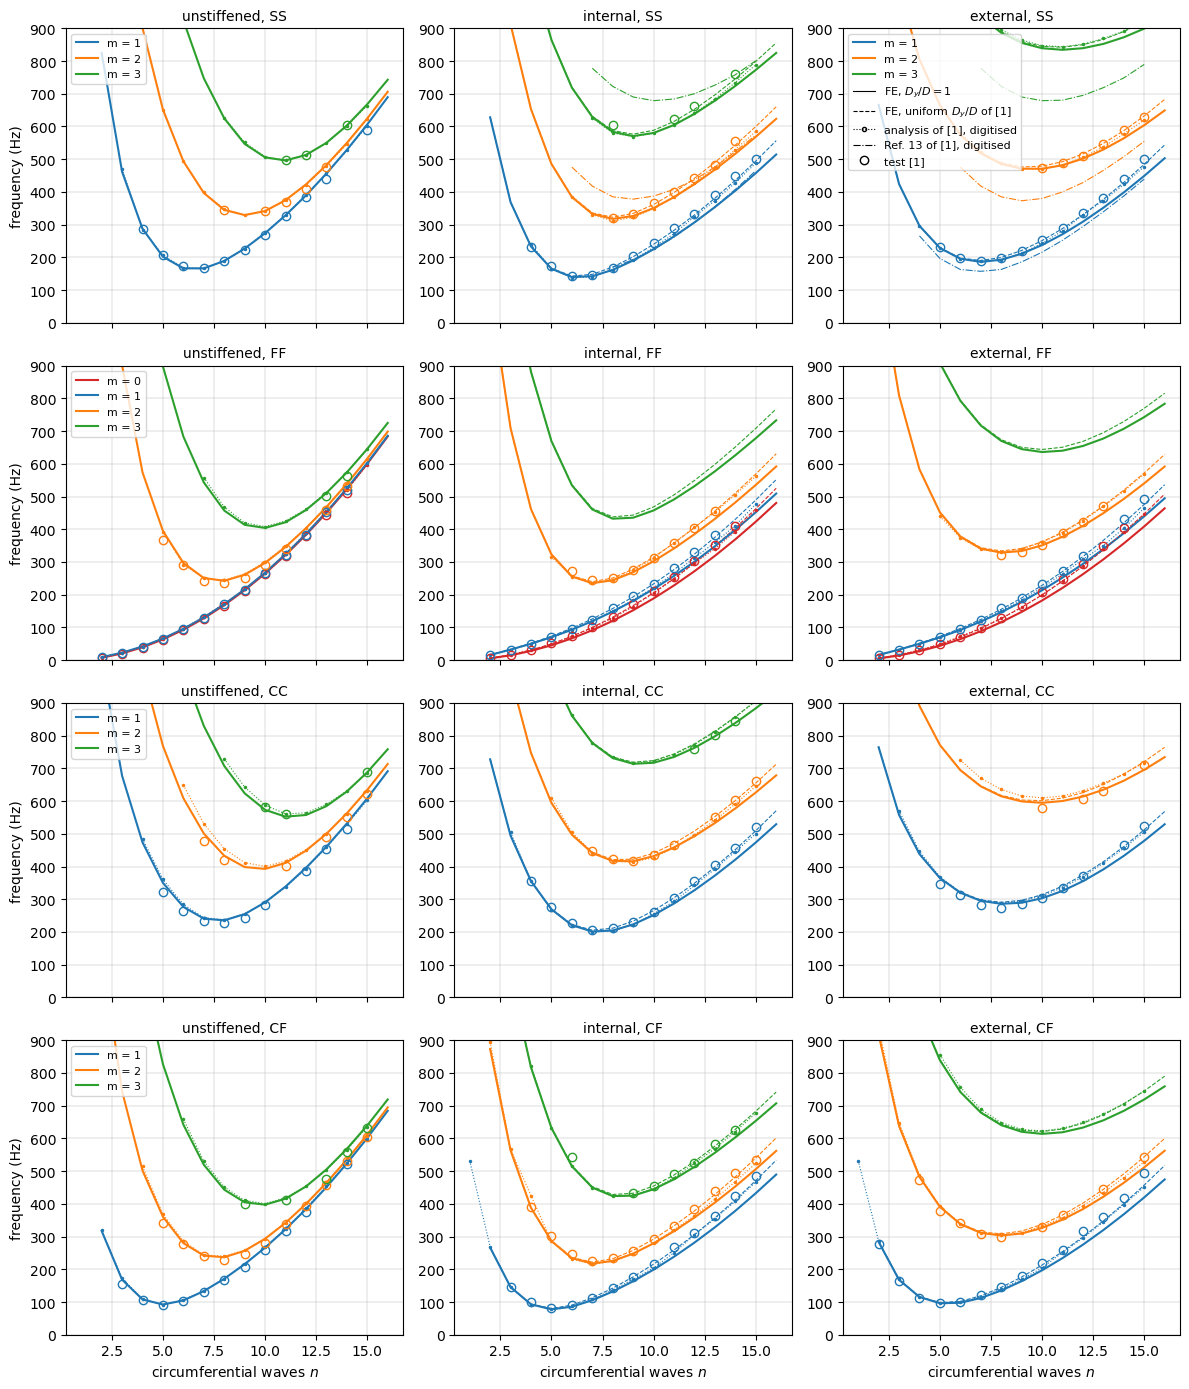

In [18]:
fig, axes = plt.subplots(4, 3, figsize=(12, 14), sharex=True)
colors = {0: 'C3', 1: 'C0', 2: 'C1', 3: 'C2'}
for row, bc in enumerate(['SS', 'FF', 'CC', 'CF']):
    for col, shell in enumerate(['unstiffened', 'internal', 'external']):
        ax = axes[row, col]
        freq = results[(shell, bc)][1]
        for m in sorted(set(mn[0] for mn in freq)):
            if m > 3:
                continue
            ns = sorted(n for (mm, n) in freq if mm == m)
            ax.plot(ns, [freq[(m, n)] for n in ns], '-', color=colors[m],
                    label='m = %d' % m)
            if shell != 'unstiffened':
                fD = results_v[(shell, bc, 'uniform')]
                nsD = sorted(n for (mm, n) in fD if mm == m)
                ax.plot(nsD, [fD[(m, n)] for n in nsD], '--', lw=0.8,
                        color=colors[m])
        for theory, style in [('present', '.:'), ('ref13', '-.')]:
            cur = curves.get((bc, shell, theory), {})
            for m in sorted(set(mn[0] for mn in cur)):
                ns = sorted(n for (mm, n) in cur if mm == m)
                ax.plot(ns, [cur[(m, n)][0] for n in ns], style, lw=0.8,
                        ms=3, color=colors[m])
        for (m, n), values in test[bc][shell].items():
            ax.plot([n], [reference(bc, m, values)], 'o', mfc='none',
                    color=colors[m])
        ax.set_ylim(0, 900)
        ax.grid(True, lw=0.3)
        ax.set_title('%s, %s' % (shell, bc), fontsize=10)
        if col == 0:
            ax.set_ylabel('frequency (Hz)')
        if row == 3:
            ax.set_xlabel('circumferential waves $n$')
    axes[row, 0].legend(loc='upper left', fontsize=8)
for style, label in [('k-', 'FE, $D_y/D = 1$'),
                     ('k--', 'FE, uniform $D_y/D$ of [1]'),
                     ('k.:', 'analysis of [1], digitised'),
                     ('k-.', 'Ref. 13 of [1], digitised'),
                     ('ko', 'test [1]')]:
    axes[0, 2].plot([], [], style, mfc='none', lw=0.8, label=label)
axes[0, 2].legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

## Minimum frequencies, external against internal stringers

[1] (report page 19) summarizes the eccentricity effect by the minimum
frequencies of the ES cylinder, higher than those of the IS cylinder by
about 34 % (SS), 35 % (FF, for the modes with $m = 2$), 39 % (CC) and 21 %
(CF); it does not say whether these are measured or computed minima (the
measured minima of Tables II to V give the SS value, the others are probably
read from the analysis of Figures 8 to 11). The same ratios from the
measured minima of the tables and from the computed minima of the model:

The lowest frequency of each cylinder and end conditions, over the computed
modes ($2 \le n \le 16$) of each variant, and over the tests:

In [19]:
published = {'SS': 34, 'FF': 35, 'CC': 39, 'CF': 21}
print('ends  family   test min IS / ES (Hz)   FE min IS / ES (Hz)   '
      'ES/IS - 1: [1]   test    FE')
for bc in ['SS', 'FF', 'CC', 'CF']:
    ratios = []
    out = []
    for source in ['test', 'FE']:
        mins = []
        for shell in ['internal', 'external']:
            if source == 'test':
                d = {mn: reference(bc, mn[0], v)
                     for mn, v in test[bc][shell].items()}
            else:
                d = results[(shell, bc)][1]
            d = {mn: f for mn, f in d.items()
                 if (mn[0] == 2 if bc == 'FF' else mn[0] >= 1)}
            mn = min(d, key=d.get)
            mins.append((mn, d[mn]))
        out.append('%5.1f %s / %5.1f %s' % (mins[0][1], mins[0][0],
                                            mins[1][1], mins[1][0]))
        ratios.append(100*(mins[1][1]/mins[0][1] - 1))
    print('%-4s  %-7s  %-22s  %-22s  %5d %%  %5.1f %%  %5.1f %%'
          % (bc, 'm = 2' if bc == 'FF' else 'all', *out, published[bc],
             *ratios))

print('\nends cylinder     test (Hz)         ' + ''.join('%-20s' % v
                                                      for v in variants))
for bc in ['SS', 'FF', 'CC', 'CF']:
    for shell in ['unstiffened', 'internal', 'external']:
        d = {mn: reference(bc, mn[0], v) for mn, v in test[bc][shell].items()}
        mn = min(d, key=d.get)
        row = '%-4s %-12s %6.1f (%d, %2d)    ' % (bc, shell, d[mn], *mn)
        for v in variants:
            f = results_v.get((shell, bc, v))
            if f is None:
                continue
            mn = min(f, key=f.get)
            row += '%6.1f (%d, %2d)      ' % (f[mn], *mn)
        print(row)

ends  family   test min IS / ES (Hz)   FE min IS / ES (Hz)   ES/IS - 1: [1]   test    FE
SS    all      142.0 (1, 6) / 189.0 (1, 7)  139.7 (1, 6) / 186.2 (1, 7)     34 %   33.1 %   33.3 %
FF    m = 2    245.0 (2, 7) / 320.0 (2, 8)  235.3 (2, 7) / 328.5 (2, 8)     35 %   30.6 %   39.6 %
CC    all      207.0 (1, 7) / 272.0 (1, 8)  201.5 (1, 7) / 286.1 (1, 8)     39 %   31.4 %   42.0 %
CF    all       81.5 (1, 5) /  95.5 (1, 5)   77.7 (1, 5) /  96.2 (1, 5)     21 %   17.2 %   23.9 %

ends cylinder     test (Hz)         D_y/D = 1           uniform             roots               
SS   unstiffened   166.0 (1,  7)     166.2 (1,  7)      
SS   internal      142.0 (1,  6)     139.7 (1,  6)       142.9 (1,  6)       143.5 (1,  6)      
SS   external      189.0 (1,  7)     186.2 (1,  7)       190.4 (1,  7)       191.1 (1,  7)      
FF   unstiffened     7.2 (0,  2)       7.2 (0,  2)      
FF   internal        6.1 (0,  2)       5.2 (0,  2)         5.7 (0,  2)         5.7 (0,  2)      
FF   externa

## Comparison with the discrete-stringer analysis of Egle and Sewall

Table 2 of [2] (page 523) gives the frequencies of the freely supported
cylinder with 60 external stringers, the ES cylinder of [1] (Table 1 of [2],
above), computed with the stringers as discrete elements ("Discrete") and
with the averaged-stiffener analysis ("Averaged"), the latter "obtained from
Ref. 14 with in-surface and eccentricity inertia terms omitted" (footnote a;
Ref. 14 of [2] is [1], then a proposed report). The discrete analysis
neglects the in-surface (in-plane) inertia of the shell too, which makes the
frequencies at small $n$ "somewhat higher than the correct values" [2] (page
522). Both use $D_y/D = 1.197$ over the whole skin (Table 1 of [2]); the
stringers of the discrete analysis are beams with the section properties of
Table 1 of [2]. [2] (page 523) finds "the agreement between the two methods
of analysis ... nearly perfect for the range of $n$ values covered. The
maximum difference is less than 1% at $n = 15$."

Two printed values are read differently:

- $m = 1$, $n = 3$, discrete: printed "44.53", read as 445.3 by the decimal
  point (the other values of the column have four significant digits), which
  is consistent with the averaged 445.1 of the same row;
- $m = 1$, $n = 12$, averaged: printed "424.2". The discrete value of the
  same row is 322.8, the averaged neighbours are 282.5 ($n = 11$) and 370.9
  ($n = 13$), and the two analyses differ by less than 1 % elsewhere (above),
  while 424.2 is 31 % above 322.8. It is shown as printed and left out of the
  statistics; it is not replaced by a guessed value.

The rows $n = 0$ (averaged column only: 2314, 2294, 2284 Hz) are not
compared: they have no discrete value, and with the in-surface inertia
omitted they are the radial (breathing) modes, while the axisymmetric modes
of the model include the in-surface inertia.

The model is compared with four variants: $D_y/D = 1$; uniform and roots as
above; and the assumptions of [2], uniform $D_y/D = 1.197$ with the inertia of
the in-surface displacements $u$, $v$ of the skin removed from the mass
matrix (`skin_inplane_inertia=False`; the stringer keeps all its inertia).
The convergence is given over the 45 compared $(m, n)$, between the two
finest meshes as above.

In [20]:
# Table 2 of [2], page 523: n: (m = 1 discrete, averaged, m = 2 discrete,
# averaged, m = 3 discrete, averaged), Hz; m = 1, n = 3, discrete printed
# "44.53", read as 445.3
egle = {
    1: (1398., 1398., 1950., 1952., 2127., 2128.),
    2: (736.5, 736.3, 1428., 1429., 1810., 1810.),
    3: (445.3, 445.1, 1059., 1059., 1514., 1514.),
    4: (304.0, 303.9, 824.1, 823.9, 1291., 1290.),
    5: (231.8, 231.8, 674.8, 674.6, 1132., 1132.),
    6: (197.7, 197.9, 579.6, 579.5, 1022., 1021.),
    7: (188.2, 188.6, 520.3, 520.4, 945.5, 945.1),
    8: (196.0, 196.7, 486.2, 486.7, 894.7, 894.6),
    9: (216.1, 217.0, 471.1, 472.0, 862.9, 863.2),
    10: (245.2, 246.3, 470.8, 472.1, 846.1, 846.8),
    11: (281.2, 282.5, 482.5, 484.2, 841.4, 842.6),
    12: (322.8, 424.2, 504.2, 506.3, 846.9, 848.6),
    13: (369.3, 370.9, 534.5, 536.9, 861.3, 863.6),
    14: (420.2, 421.9, 572.1, 574.9, 883.6, 886.5),
    15: (475.2, 477.1, 616.2, 619.4, 913.2, 916.6),
}
excluded = {(1, 12, 'averaged')}

evariants = {
    'D_y/D = 1': ({}, (meshes['SS'][-2], final['SS'])),
    'uniform': (dict(Dy_factor=Dy['external']),
                (meshes['SS'][-2], final['SS'])),
    'roots': (None, (final['SS'], doubled(final['SS']))),
    'as [2]': (dict(Dy_factor=Dy['external'], skin_inplane_inertia=False),
               (meshes['SS'][-2], final['SS'])),
}
tasks = []
for v, (opts, ms) in evariants.items():
    for mesh in ms:
        o = dict(opts) if opts is not None else dict(
            Dy_factor=root_factors('external', mesh[1]))
        o.update(ns=range(1, 16), k=16)
        tasks.append(('external', 'SS', mesh, o, v))
t0 = time.time()
out = pmap(spectrum, [t[:4] for t in tasks])
print('%.0f s' % (time.time() - t0))
eres = {(t[4], t[2]): r[1] for t, r in zip(tasks, out)}
keys = [(m, n) for m in [1, 2, 3] for n in range(1, 16)]
freq_e = {}
for v, (opts, ms) in evariants.items():
    f0 = np.array([eres[(v, ms[0])].get(mn, np.nan) for mn in keys])
    f1 = np.array([eres[(v, ms[1])].get(mn, np.nan) for mn in keys])
    dd = np.abs(f1/f0 - 1)
    i = np.nanargmax(dd)
    print('%-10s %s -> %s: largest change %.2f %% at (%d, %2d)'
          % (v, ms[0], ms[1], 100*dd[i], *keys[i]))
    freq_e[v] = eres[(v, ms[1])]

print('\n m   n | discrete averaged [2] | ' + ' | '.join(
    '%-15s' % v for v in evariants) + ' (diff from discrete)')
diffs = {}
for m, n in keys:
    row = '%2d %3d | %8.1f %8.1f%s |' % (
        m, n, *egle[n][2*(m - 1):2*m],
        '(x)' if (m, n, 'averaged') in excluded else '   ')
    for v in evariants:
        fe = freq_e[v].get((m, n), np.nan)
        row += ' %7.1f %+6.1f%% |' % (fe, 100*(fe/egle[n][2*(m - 1)] - 1))
        for j, kind in enumerate(['discrete', 'averaged']):
            if (m, n, kind) in excluded:
                continue
            dv = fe/egle[n][2*(m - 1) + j] - 1
            diffs.setdefault((v, kind, 'all n'), []).append(dv)
            if n >= 4:
                diffs.setdefault((v, kind, 'n >= 4'), []).append(dv)
    print(row)
print('(x): printed 424.2, left out of the statistics')
print('\nvariant     column     n        values   mean    min    max')
for (v, kind, rng), dv in diffs.items():
    print('%-11s %-10s %-7s %5d  %+6.1f %+6.1f %+6.1f'
          % (v, kind, rng, *stats(dv)))

378 s
D_y/D = 1  (49, 8, 6) -> (97, 12, 8): largest change 0.09 % at (3, 11)
uniform    (49, 8, 6) -> (97, 12, 8): largest change 0.09 % at (3, 11)
roots      (97, 12, 8) -> (97, 24, 8): largest change 0.06 % at (3,  1)
as [2]     (49, 8, 6) -> (97, 12, 8): largest change 0.09 % at (3, 11)

 m   n | discrete averaged [2] | D_y/D = 1       | uniform         | roots           | as [2]          (diff from discrete)
 1   1 |   1398.0   1398.0    |  1117.8  -20.0% |  1119.6  -19.9% |  1123.1  -19.7% |  1231.1  -11.9% |
 1   2 |    736.5    736.3    |   666.0   -9.6% |   666.3   -9.5% |   667.1   -9.4% |   698.0   -5.2% |
 1   3 |    445.3    445.1    |   424.2   -4.7% |   424.3   -4.7% |   424.7   -4.6% |   435.0   -2.3% |
 1   4 |    304.0    303.9    |   296.3   -2.5% |   296.6   -2.4% |   296.9   -2.3% |   301.0   -1.0% |
 1   5 |    231.8    231.8    |   228.5   -1.4% |   229.4   -1.1% |   229.7   -0.9% |   231.6   -0.1% |
 1   6 |    197.7    197.9    |   195.8   -1.0% |   197.9   +0.1

### The results of the model in a file

The frequencies of all variants are written to
`results/sewall1968_model_frequencies.csv` (columns: `study`, `tests` for
the spectra of the measured modes, `egle` for the ES cylinder with SS ends,
$1 \le n \le 15$; `ends`, `shell`, `variant`, `m`, `n`, `f_Hz`).

In [21]:
with open('results/sewall1968_model_frequencies.csv', 'w', newline='') as f:
    f.write('# Natural frequencies of the discrete-stringer model of the '
            'notebook sewall1968_stiffened_cylinder_frequencies.ipynb\n'
            '# (bfsccylinder skin + bfscplate2d stringers), finest meshes; '
            'variants: D_y/D = 1, uniform D_y/D of Sewall and Naumann\n'
            '# appendix A, D_y at the roots, and as [2] (uniform 1.197, no '
            'in-surface inertia of the skin). f_Hz in Hz.\n')
    w = csv.writer(f)
    w.writerow(['study', 'ends', 'shell', 'variant', 'm', 'n', 'f_Hz'])
    for (shell, bc, v), fv in sorted(results_v.items()):
        for (m, n), fr in sorted(fv.items()):
            if m <= 4:
                w.writerow(['tests', bc, shell, v, m, n, '%.2f' % fr])
    for v, fv in freq_e.items():
        for (m, n), fr in sorted(fv.items()):
            if m <= 3:
                w.writerow(['egle', 'SS', 'external', v, m, n, '%.2f' % fr])
print('written')

written


## Mode shapes

The normal displacement $w$ of the skin over the developed cylinder, rebuilt
from the sector by the factors $e^{i n k \phi}$, for the lowest measured
mode of each end condition, internal and external stringers; the stringers
are not drawn (60 lines at $6°$ spacing). The position along $x$ runs from
the bottom ($x = 0$, the clamped end for CF) to the top.

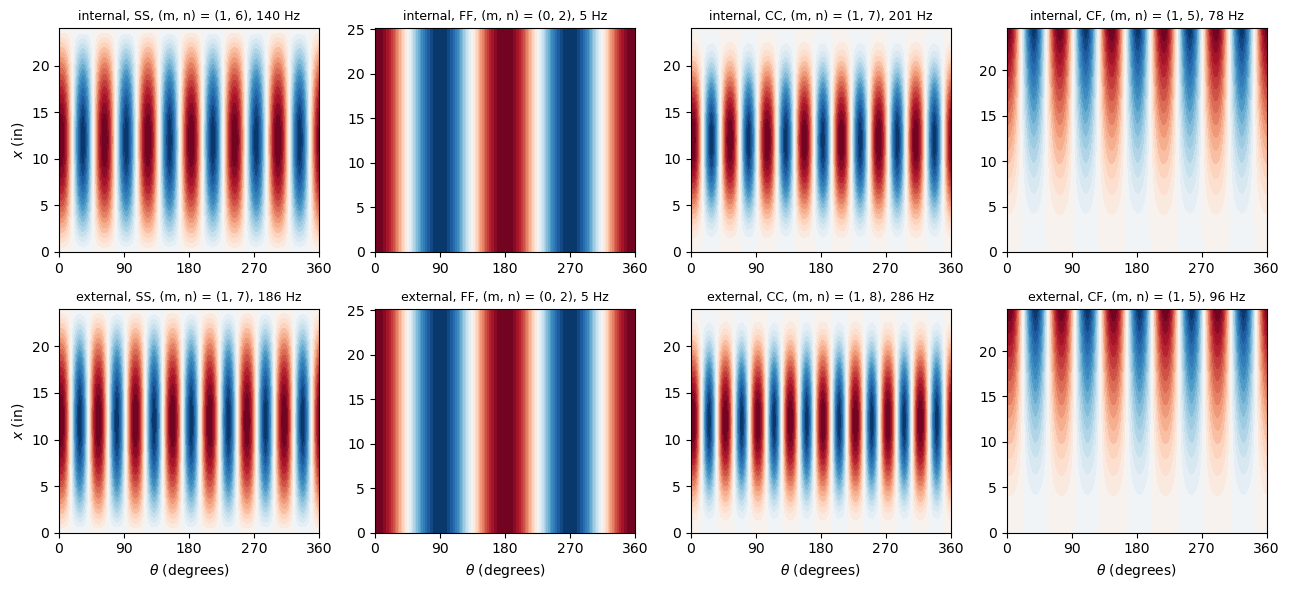

In [22]:
def plot_w(ax, model, mode, n, title):
    w = normalize_phase(model.skin_field(mode, W))
    theta, wfull = model.full_circumference(w, n)
    lim = np.abs(wfull).max()
    ax.contourf(np.degrees(theta), model.xlin, wfull,
                levels=np.linspace(-lim, lim, 31), cmap='RdBu_r')
    ax.set_title(title, fontsize=9)


fig, axes = plt.subplots(2, 4, figsize=(13, 6), sharey=False)
for row, shell in enumerate(['internal', 'external']):
    for col, bc in enumerate(['SS', 'FF', 'CC', 'CF']):
        model = build(shell, bc, *final[bc])
        _, freq, modes = results[(shell, bc)]
        d = {mn: f for mn, f in freq.items() if mn in test[bc][shell]}
        mn = min(d, key=d.get)
        plot_w(axes[row, col], model, modes[mn], mn[1],
               '%s, %s, (m, n) = %s, %.0f Hz' % (shell, bc, mn, d[mn]))
        axes[row, col].set_xticks([0, 90, 180, 270, 360])
for ax in axes[1]:
    ax.set_xlabel(r'$\theta$ (degrees)')
for ax in axes[:, 0]:
    ax.set_ylabel('$x$ (in)')
plt.tight_layout()
plt.show()

The cross-section at mid-length of the lowest SS modes, the skin (black) and
the 60 stringers (red), the displacements greatly magnified: the stringers
follow the radial displacement and the rotation of the skin at their root.

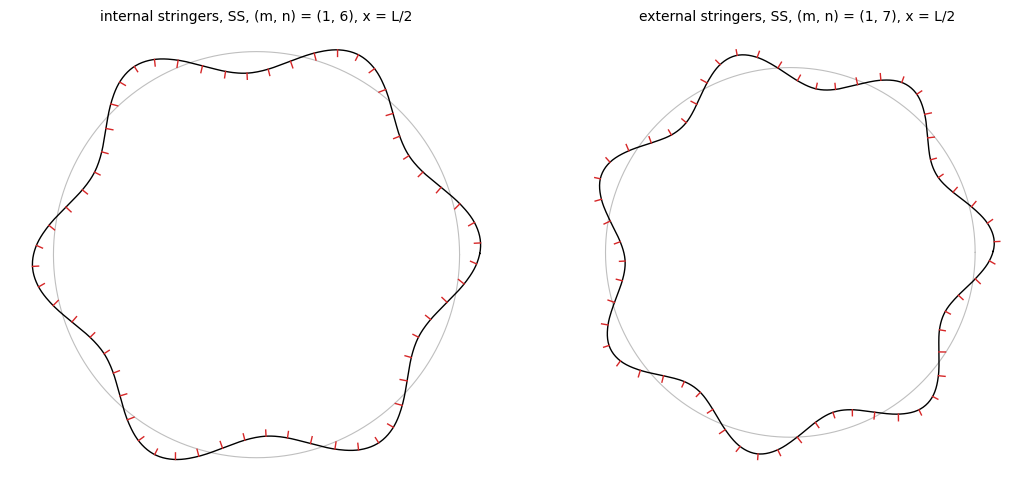

In [23]:
def plot_section(ax, model, mode, n, scale):
    i = model.nx//2
    R = model.R
    w = normalize_phase(mode)
    theta, wf = model.full_circumference(model.skin_field(w, W), n)
    _, vf = model.full_circumference(model.skin_field(w, V), n)
    norm = scale/np.abs(wf[i]).max()
    ax.plot(R*np.cos(theta), R*np.sin(theta), color='0.75', lw=0.8)
    r = R + norm*wf[i]
    t = theta + norm*vf[i]/R
    ax.plot(r*np.cos(t), r*np.sin(t), 'k', lw=1)
    nodes = model.str_nodes[i]
    r0 = R + model.Y
    for k in range(model.nstringers):
        ths = (k + 0.5)*model.phi
        fac = np.exp(1j*n*k*model.phi)
        Vs = np.real(w[DOF*nodes + V]*fac)
        Ws = np.real(w[DOF*nodes + W]*fac)
        r = r0 + norm*Vs
        t = ths + norm*Ws/r0
        ax.plot(r*np.cos(t), r*np.sin(t), 'C3', lw=1)
    ax.set_aspect('equal')
    ax.axis('off')


fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, shell in zip(axes, ['internal', 'external']):
    model = build(shell, 'SS', *final['SS'])
    _, freq, modes = results[(shell, 'SS')]
    d = {mn: f for mn, f in freq.items() if mn in test['SS'][shell]}
    mn = min(d, key=d.get)
    plot_section(ax, model, modes[mn], mn[1], scale=1.)
    ax.set_title('%s stringers, SS, (m, n) = %s, x = L/2' % (shell, mn),
                 fontsize=10)
plt.tight_layout()
plt.show()

## Discussion

**Unstiffened cylinder.** The model reproduces the measured frequencies of
the unstiffened cylinder within a few per cent for the four end conditions
(mean differences +0.6 % to +2.7 %), which validates the material data, the
identification of $(m, n)$ and the idealized end conditions. It also agrees
with the analysis of [1] (Figures 8(a) to 11(a)): on average within −1.2 % to
−0.1 %, and within the reading precision for 13 of 19 (SS), 22 of 37 (FF), 7
of 18 (CC) and 14 of 27 (CF) measured modes. The model is stiffer than the
tests for CC and CF ends at small $n$ (up to about 8 %), and so is the
analysis of [1], by up to 11.6 % for CC ends: [1] (report page 19) attributes
its differences of "almost 10 percent" to "the in-plane shear contradiction
inherent in the analysis" (beam functions, report page 15) and, "to a lesser
extent, to some external loading (due to the potting of the ends)". The model
has no such contradiction; the potted ends are less rigid than a perfect
clamp.

**Stiffened cylinders, stringers joined along a line ($D_y/D = 1$).** The
model is below the tests by 3.4 % to 6.7 % on average (except the
externally stiffened cylinder with CC ends, −0.1 %), and the difference grows
with $n$, to about −10 % for $m = 1$, $n = 15$, and −15 % for the FF modes
with $m = 0$, $n = 2$. These are the modes that bend the skin around the
circumference. The mesh is not the cause: the measured modes change by less
than 1 % between the two finest meshes.

**The circumferential bending stiffness at the roots.** Appendix A of [1] is
recomputed above from Table I and its printed factors are correct (1.1952 and
1.1966 against 1.195 and 1.197). With them the mean differences from the
tests fall to −1.4 % to +2.8 % (uniform) and −0.3 % to +3.6 % (roots), in all
eight cases, and the SS modes with $m = 1$ to −4.9 % to +1.5 % (uniform) and
−4.6 % to +2.1 % (roots). The factor raises the SS mode $m = 1$, $n = 15$ by
8 % (457.5 to 494.3 Hz IS, 449.0 to 484.5 Hz ES), close to the 9 % that [1]
(report page 17) finds with its analysis. Its value is an estimate: the
strain-energy argument is "limited to the case of pure bending" with "the
neutral surface occurring at the midheight", and "the choice of $h(y)$ is
somewhat arbitrary" (report page 23); for the same geometry, (A7) and (A8)
give 1.29 (rigid roots) and 1.11 (no fillets), so that the fillets, which
the plate stringer of the model does not have, carry most of the correction.
Smeared over the skin or concentrated at the roots, the same compliance per
bay does not give the same frequencies: the roots variant is 0.1 % to 2.2 %
above the uniform one for the SS modes with $m = 1$ (e.g. 495.0 against 484.5
Hz, ES, $n = 15$), since these modes do not bend the skin under a uniform
moment. The two variants bracket the tests about equally well (SS: −1.0 %
and +0.2 % IS, −0.3 % and +0.9 % ES); the uniform one is the assumption of
[1] and [2].

**Against the analysis of [1].** With $D_y/D = 1$ the model is below the
curves of [1] (mean −1.4 % to −5.8 %), with the uniform $D_y/D$ above them
(+0.4 % to +2.7 %, at most +5.8 %), and the curves of [1] are themselves
below the tests for the stiffened cylinders (mean −0.8 % to −3.6 %, except
CC ES, +2.4 %). The model with the same $D_y/D$ as [1] is therefore closer
to the tests than the analysis of [1] for these cylinders. Sources of the
difference between the two analyses, from the numbers above and the text of
[1]:

- smeared against discrete stringers: small for 60 stringers, since the two
  analyses of [2] differ by "less than 1%" (Table 2 of [2]);
- the torsional stiffness of the stringer: $G b_s^3 H_s/3 = 366.5$ lbf
  in$^2$ for the plate of the model against $(GJ)_s = 269.8$ lbf in$^2$ of
  [2] (Saint-Venant value of the rectangle, reproduced above within 0.3 %),
  36 % more, which raises the model;
- the coupling term $D_1/D = 0.346$ of [1] (report page 17), not raised in
  the variants of the model, which would raise [1], not the model;
- the kinematics, Novozhilov's in [1] (report page 11), Sanders-type in the
  model, and the beam functions along $x$ of [1] for ends other than SS,
  with the in-plane shear contradiction at clamped ends (report page 15);
- the section of the stringer: the plate omits the fillets and overlaps the
  skin over $h/2$, its area is 1.2 % (IS) and 1.4 % (ES) below $A_s$ and its
  polar moment about the middle surface 0.7 % below $J_{e_s}$ of Table I.

**Against the discrete analysis of [2].** For $n \ge 4$ the uniform variant
is +0.6 % (−2.4 % to +2.7 %) from the discrete column of Table 2 of [2] and
+0.4 % (−2.4 % to +2.2 %) from the averaged one. For $n \le 3$ the model is
below [2], down to −19.9 % for $m = 1$, $n = 1$. With the assumptions of [2]
(uniform $D_y/D$, no in-surface inertia of the skin) the model rises to
−11.9 % ($m = 1$, $n = 1$), −5.2 % ($n = 2$) and −2.3 % ($n = 3$), and +1.0 %
(−1.0 % to +2.8 %) for $n \ge 4$: the neglect of the in-surface inertia
explains most of the difference at small $n$, as [2] (page 522) expects. The
rest at $n = 1$ is not explained by the skin alone; [2] neglects "the
in-surface inertias", which may include those of the stringers, kept in the
model. For the two printed values discussed above: the model gives 424.3 Hz
(uniform) and 435.0 Hz (assumptions of [2]) at $m = 1$, $n = 3$, 2.3 % below
445.3, in line with its neighbours ($n = 2$: −5.2 %, $n = 4$: −1.0 %), which
supports the reading 445.3; at $m = 1$, $n = 12$ it gives 330.9 Hz, 2.5 %
above the discrete 322.8 and 22 % below the printed averaged 424.2, a value
that would contradict the statement of [2] that its two analyses differ by
less than 1 %.

**End conditions and specimens.** With $D_y/D$ the largest remaining
differences are the FF modes with $m = 0$ and small $n$ (below the tests,
within the ±2 Hz reading precision of the curves of [1] for $n \le 5$) and
the CC ends of the externally stiffened cylinder, above the tests (+2.8 %
mean, uniform; the lowest mode, $(1, 8)$, 290.8 Hz against 272.0 Hz). [1]
(report page 20) finds the closer agreement for the internally stiffened
cylinder with CC ends "not readily explainable, although the externally
stiffened shell may have been subjected to more external loading"; its
measured ES/IS ratio of the minimum CC frequencies, 31.4 %, is below that of
the model, 42.0 %, and of its own value, 39 %. For SS ends, the rings with
sharp tips did not restrain the normal displacement of the shell between
the stringers on the stiffened side (report page 7), while the model
restrains it along the whole edge. Other sources not modelled: the two
longitudinal seams of each cylinder (report page 6), and the scatter of the
skin thickness, of which Table I gives only the averages: a change of
$\pm 0.0010$ in, the difference between the two stiffened skins, changes the
SS frequencies by about ±2 % on average and up to ±4 %.

**Eccentricity.** The external stringers raise the minimum frequencies
above those of the internal stringers in the model as in the tests. For SS
ends the ratio of the minima agrees with the tests and with the 34 % of
[1]; for FF ($m = 2$), CC and CF ends the model gives larger ratios than
the measured minima: closer to the values quoted by [1] for CC and CF ends,
about as far above the 35 % of [1] for FF ($m = 2$) as the measured minima
are below it.